# 12. HOG texture distance

Histogram of oriented gradients of every patch, compared with the good-fabric reference from good_cal tiles. Sensitive to changes in edge direction.

Method: `filters.py` (`METHOD_NAME = "hog"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/hog/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "hog"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
PATCH = 32                # patch size (px)
STRIDE = 16               # step between patches (px)
method = None


def fit(cal_tiles):
    """Reference = HOG features of good_cal patches only."""
    ref = F.fit_patch_reference(cal_tiles, F.hog_feature, STEPS, PATCH, STRIDE)
    return lambda tile: F.hog_anomaly(tile, STEPS, PATCH, STRIDE, ref=ref)

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 2.14   pixel threshold 2.14

                    predicted OK   predicted DAMAGED
good + hard neg.             409                 238
defect                        20                  18

false alarm rate    0.7% good_test, 46.7% hard negatives
recall              47.4%  (small <50 px: 21.7% of 23, large: 86.7% of 15)
strip level         false alarm 10.0% of 10 good strips, recall 47.4% of 38 defect strips
precision           7.0%
F1                  0.122
AUROC               0.607   (threshold-free ranking quality)
mean IoU            0.012 over all defect tiles, 0.025 over detected ones
time                24.9 ms/tile (median), fitting on good_cal 3.8 s
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\hog


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

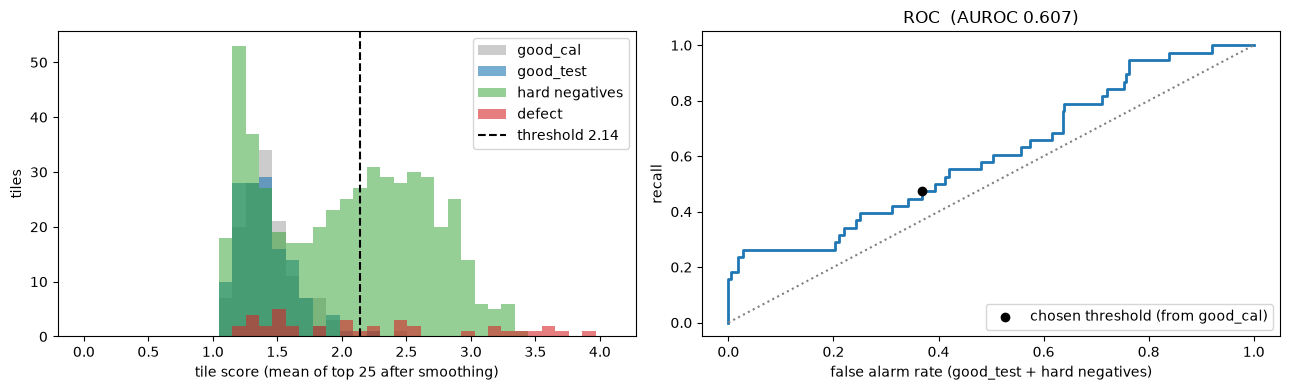

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.00          151          1.33
006          7      7     100%      0.04         1260          3.59
019         23      5      22%      0.00           15          1.52
023          3      3     100%      0.06          778          3.14
030          4      3      75%      0.00           70          2.32


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

20 missed defects, 238 false alarms


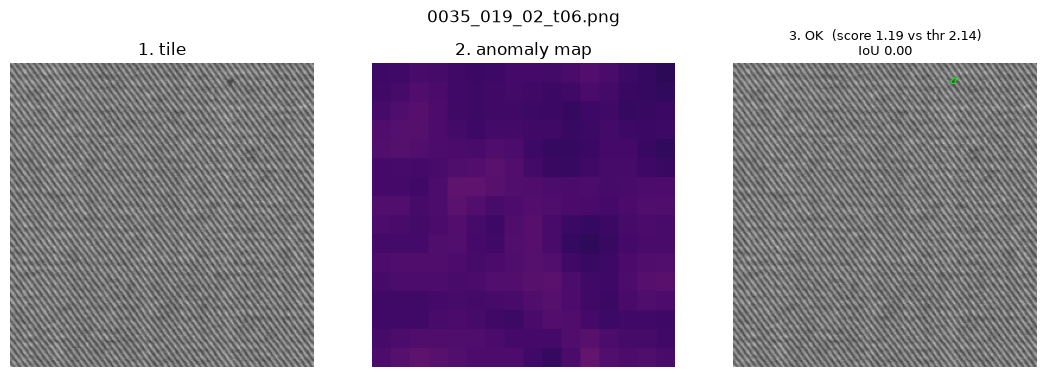

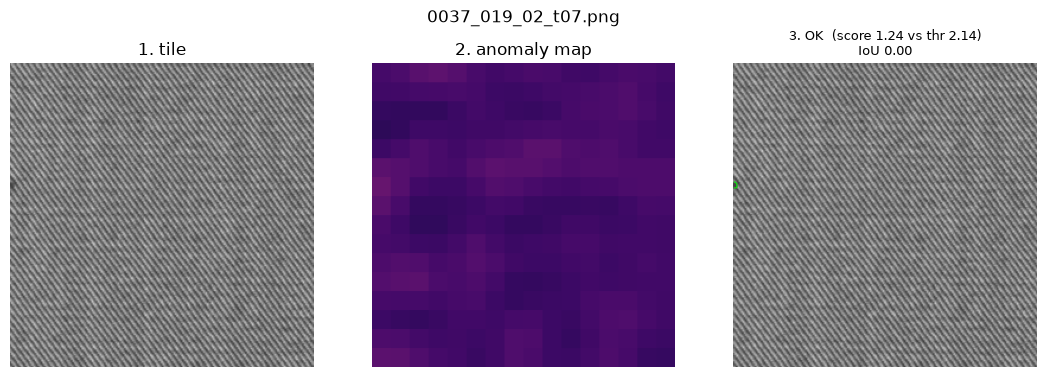

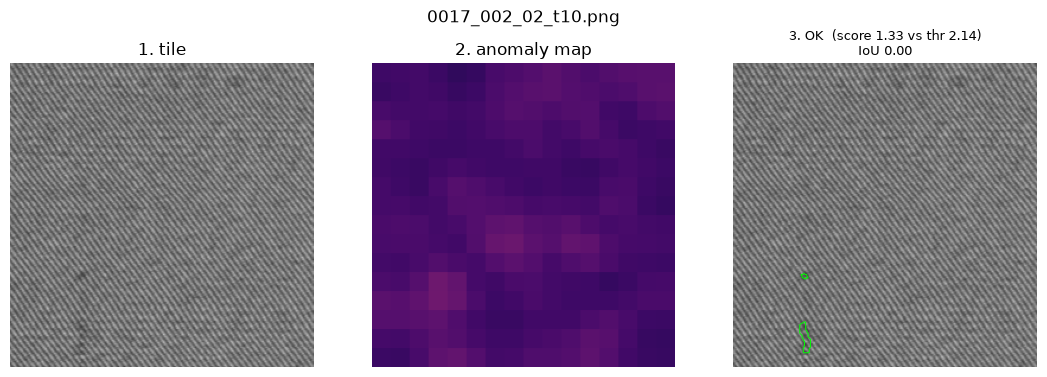

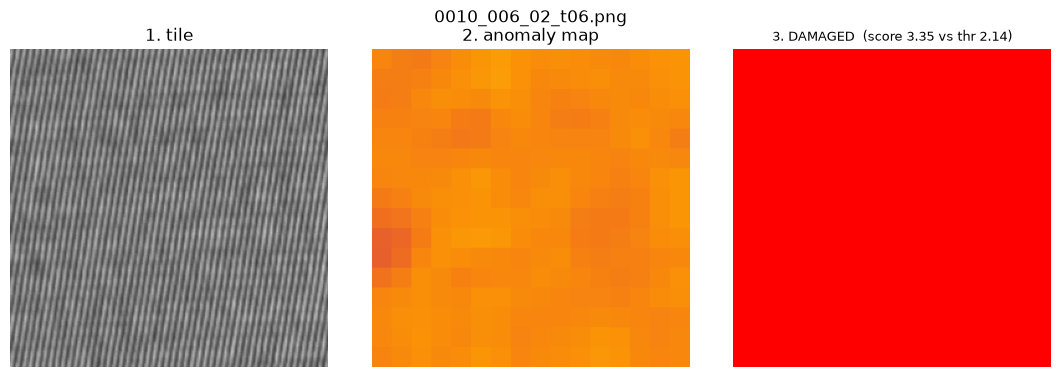

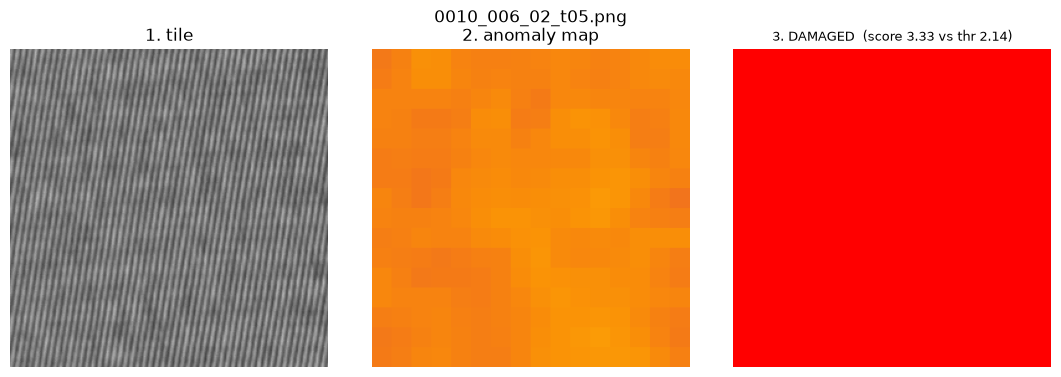

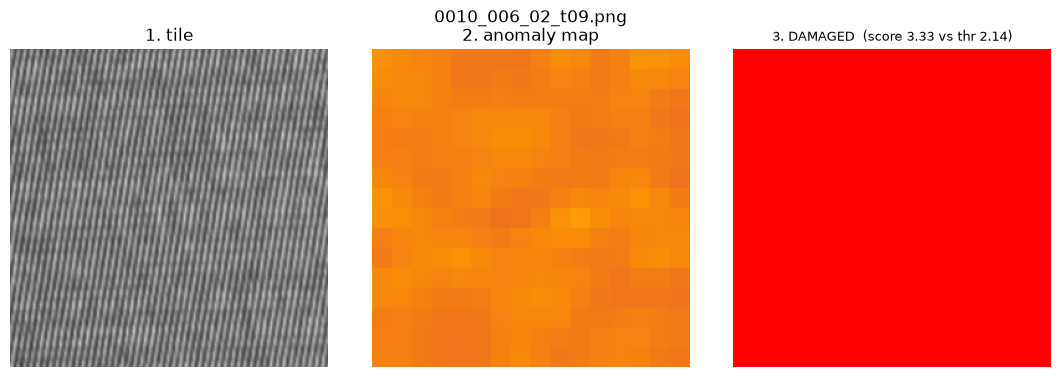

In [5]:
E.show_failures(res, n=3)

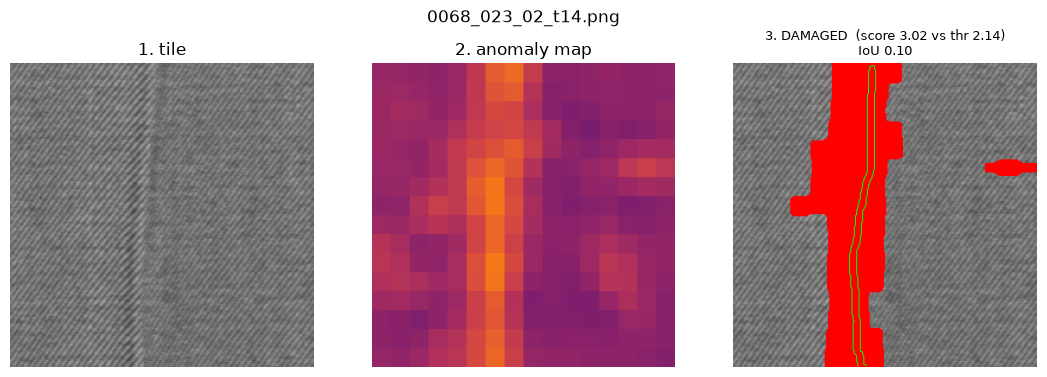

In [8]:
E.show_detection(E.OUT / "defect" / "0068_023_02_t14.png", res)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


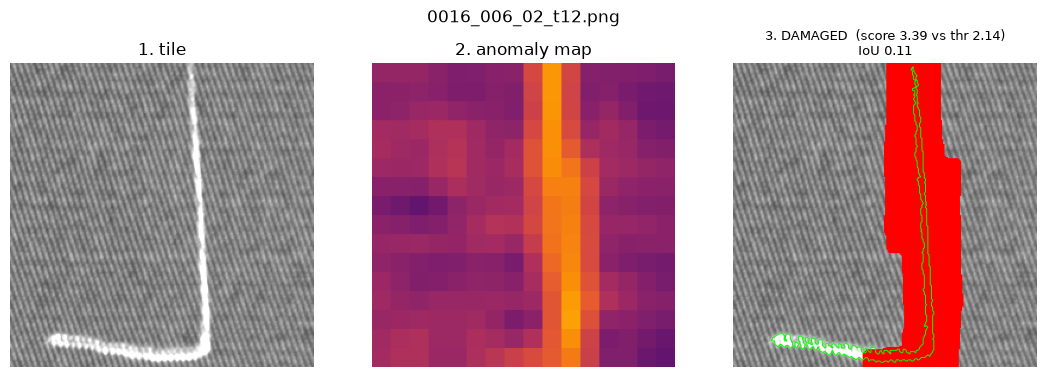

smallest defect: 0025_019_02_t10.png, 8 px


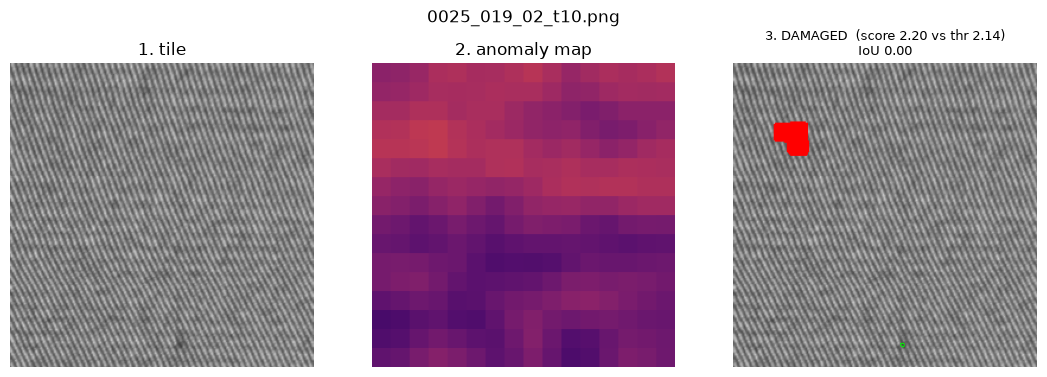

good tile: 0020_000_02_t15.png


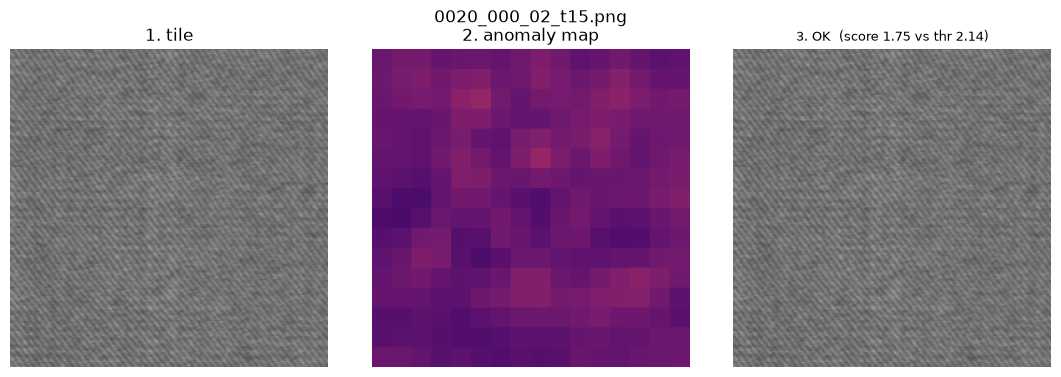

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

In [ ]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   0.0%   31.6%   55.6%   0.0%  62.5%     0.0%    71.4%  0.892  0.03  28.1
01        154   146     28   6.5%   18.5%   82.1%  50.0%  84.6%    90.9%    66.7%  0.927  0.25  27.7
02        140   507     38   0.7%   46.7%   47.4%  21.7%  86.7%    10.0%    47.4%  0.607  0.01  24.5
03        110   256     89   0.0%    9.0%   41.6%  23.1%  44.7%     0.0%    56.7%  0.803  0.04  23.8
04        138   129     12   5.8%   17.1%   16.7%   0.0%  28.6%    80.0%    10.0%  0.570  0.00  23.8
05        150    13      1   2.0%    0.0%    0.0%    n/a   0.0%    30.0%     0.0%  0.902  0.00  23.1
06        143    81      7  18.2%   27.2%   71.4%  60.0% 100.0%   100.0%    66.7%  0.740  0.00  23.6
-------------------------------------------------------------------------------------------